# House Price Prediction Using Linear Regression

**Name:** Mohini More  
**Organization:** Oasis Infobyte  
**Internship Track:** Data Analytics  
**Task:** Level 2 — Task 1  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Jupyter Notebook

## Project Objective

The objective of this project is to develop a Linear Regression model to predict house prices based on selected housing features. The project includes data exploration, feature selection, model training, and evaluation using MSE, RMSE, and R² Score.

Ridge and Lasso Regression are also explored to compare their performance with the Linear Regression model. The findings help understand the relationships between housing features and house prices and evaluate the model's predictive performance.



## 1. Importing Required Libraries




In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!



## 2. Loading the Dataset




In [4]:

df = pd.read_csv("C:/OASIS Data Analytics Project/House-Price-Prediction-clean.csv")

df.head()


,Id,MSSubClass,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,60,8450,7,5,2003,2003,706,150,856,...,0,61,0,0,0,0,0,2,2008,208500
1,2,20,9600,6,8,1976,1976,978,284,1262,...,298,0,0,0,0,0,0,5,2007,181500
2,3,60,11250,7,5,2001,2002,486,434,920,...,0,42,0,0,0,0,0,9,2008,223500
3,4,70,9550,7,5,1915,1970,216,540,756,...,0,35,272,0,0,0,0,2,2006,140000
4,5,60,14260,8,5,2000,2000,655,490,1145,...,192,84,0,0,0,0,0,12,2008,250000



## 3.  Data Inspection




In [5]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (1460, 32)

Column Names:
['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'BsmtFullBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 32 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Id             1460 non-null   int64
 1   MSSubClass     1460 non-null   int64
 2   LotArea        1460 non-null   int64
 3   OverallQual    1460 non-null   int64
 4   OverallCond    1460 non-null   int64
 5   YearBuilt      1460 non-null   int64
 6   YearRemodAdd   1460 non-null   int64
 7   BsmtFinSF1     1460 non-null

In [6]:

# Check missing values
df.isnull().sum()


Id               0
MSSubClass       0
LotArea          0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
BsmtFinSF1       0
BsmtUnfSF        0
TotalBsmtSF      0
1stFlrSF         0
2ndFlrSF         0
GrLivArea        0
BsmtFullBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
TotRmsAbvGrd     0
Fireplaces       0
GarageCars       0
GarageArea       0
WoodDeckSF       0
OpenPorchSF      0
EnclosedPorch    0
3SsnPorch        0
ScreenPorch      0
PoolArea         0
MiscVal          0
MoSold           0
YrSold           0
SalePrice        0
dtype: int64


## 4. Descriptive Statistics




In [7]:

# Calculate descriptive statistics
df.describe().round(2)


,Id,MSSubClass,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.0,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,...,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,730.50,56.9,10516.83,6.10,5.58,1971.27,1984.87,443.64,567.24,1057.43,...,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.2
std,421.61,42.3,9981.26,1.38,1.11,30.20,20.65,456.10,441.87,438.71,...,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.5
min,1.00,20.0,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.0
25%,365.75,20.0,7553.50,5.00,5.00,1954.00,1967.00,0.00,223.00,795.75,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.0
50%,730.50,50.0,9478.50,6.00,5.00,1973.00,1994.00,383.50,477.50,991.50,...,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.0
75%,1095.25,70.0,11601.50,7.00,6.00,2000.00,2004.00,712.25,808.00,1298.25,...,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.0
max,1460.00,190.0,215245.00,10.00,9.00,2010.00,2010.00,5644.00,2336.00,6110.00,...,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.0



### 4.1 Statistical Summary of Sale Price

The SalePrice variable is the target variable of this project. Its statistical summary helps us understand the typical house price and the variation in prices.


In [8]:

print("Mean Sale Price:", round(df["SalePrice"].mean(), 2))
print("Median Sale Price:", round(df["SalePrice"].median(), 2))
print("Mode Sale Price:", round(df["SalePrice"].mode()[0], 2))
print("Standard Deviation:", round(df["SalePrice"].std(), 2))

Mean Sale Price: 180921.2
Median Sale Price: 163000.0
Mode Sale Price: 140000
Standard Deviation: 79442.5



## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of House Prices

The distribution of SalePrice is visualized using a histogram with a KDE curve. This helps us understand how house prices are distributed and identify possible skewness.


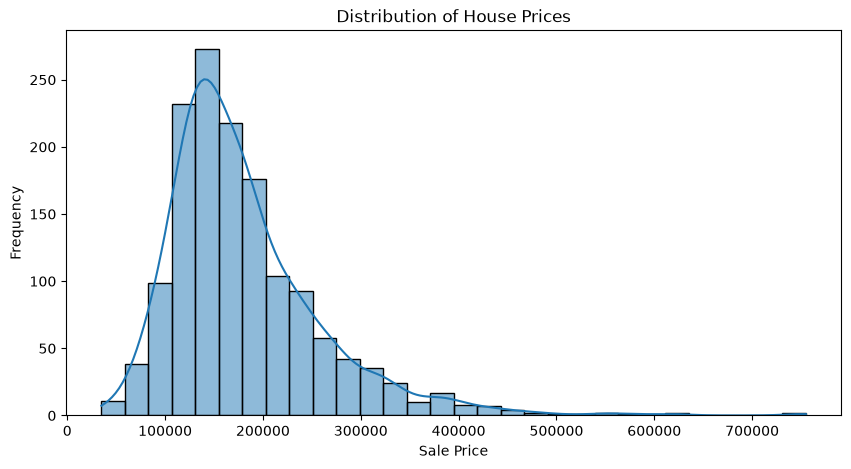

In [9]:

plt.figure(figsize=(10, 5))

sns.histplot(df["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()



**Observation:**

The distribution of house prices is positively skewed, indicating that most houses are concentrated in the lower to middle price ranges, while a smaller number of houses have considerably higher prices.



## 6. Correlation Analysis

A correlation coefficient ranges from -1 to +1:
- +1 indicates a strong positive relationship.
- -1 indicates a strong negative relationship.
- 0 indicates little or no linear relationship.

This analysis helps identify features that may be useful for predicting house prices.


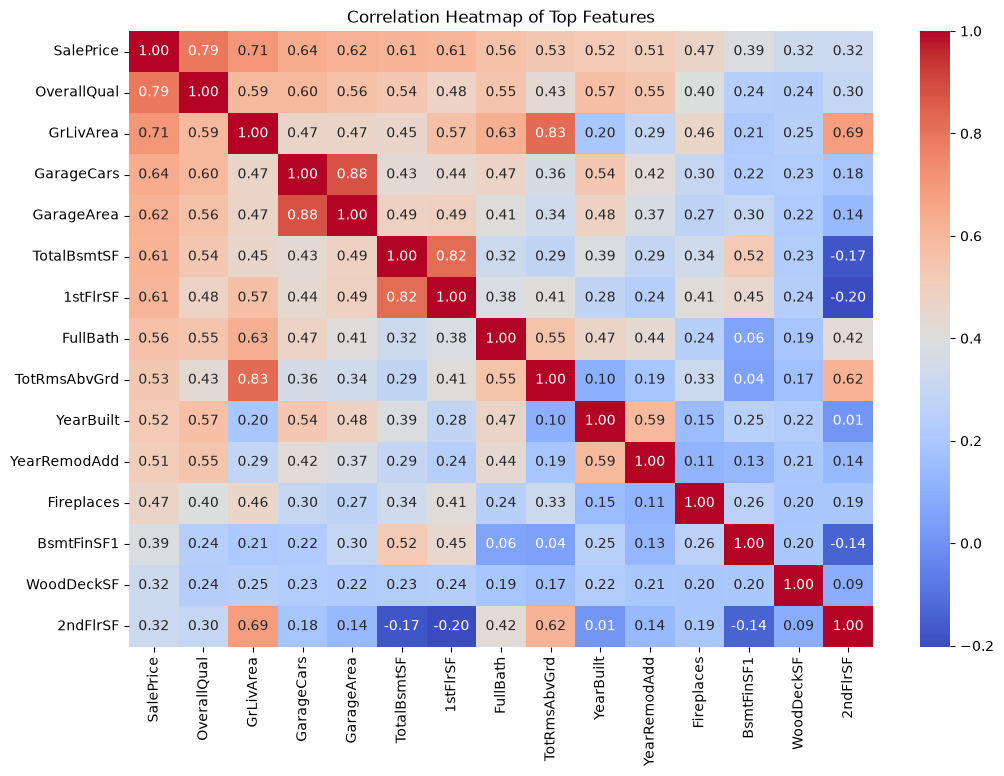

In [10]:

# Correlation matrix
correlation = df.corr()

# The 15 features most correlated with SalePrice
top_features = correlation["SalePrice"].abs().sort_values(
    ascending=False
).head(15).index

# Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Top Features")
plt.show()



###  Interpretation:

The correlation heatmap shows the relationships between numerical features and SalePrice.

Features with strong positive correlations tend to increase with house prices, while features with negative correlations tend to decrease as house prices increase.

Correlation helps identify potentially useful predictors for the Linear Regression model. However, correlation does not necessarily imply causation.



## 7. Feature Selection

Feature selection is the process of identifying the most relevant variables for predicting house prices.

Based on the correlation analysis and knowledge of housing characteristics, the following features are selected:

- **OverallQual:** Overall quality of the house.
- **GrLivArea:** Above-ground living area.
- **GarageCars:** Garage capacity in number of cars.
- **TotalBsmtSF:** Total basement area.
- **FullBath:** Number of full bathrooms.
- **YearBuilt:** Year the house was constructed.
- **YearRemodAdd:** Year of remodeling or addition.
- **Fireplaces:** Number of fireplaces.

These features are selected because they represent important characteristics of residential properties and show meaningful relationships with SalePrice.

The target variable is SalePrice, which represents the house's sale price.

Some highly correlated features may contain overlapping information, so a smaller feature set is used to keep the model simple.



## 8. Preparing Features and Target Variable

In this section, the selected independent variables are stored in X, while SalePrice is stored in y as the dependent variable.

The model will use X to predict the target variable y.


In [11]:

# Select independent variables
features = [ "OverallQual","GrLivArea","GarageCars","TotalBsmtSF","FullBath","YearBuilt","YearRemodAdd","Fireplaces"]

X = df[features]

# Target variable
y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1460, 8)
Target shape: (1460,)



## 9. Train-Test Split

The dataset is divided into training and testing sets using the train_test_split() function from scikit-learn.

- Training set (80%): Used to train the Linear Regression model.
- Testing set (20%): Used to evaluate the model on unseen data.

A random_state value is used to ensure reproducibility of the results.


In [12]:

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.20,random_state=42)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (1168, 8)
Testing Features: (292, 8)
Training Target: (1168,)
Testing Target: (292,)



## 10. Model Training Using Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

In this project, the model learns the relationship between house features and SalePrice using the training dataset.

The trained model will then be used to predict house prices in the testing dataset.


In [13]:

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!



## 11. House Price Prediction

After training the Linear Regression model, predictions are generated using the testing dataset.

The model predicts house prices based on the selected features. These predicted values will later be compared with actual house prices to evaluate model performance.



### 11.1 Comparison of Actual and Predicted House Prices

The following table compares the actual sale prices with the prices predicted by the Linear Regression model for the test dataset.

The original dataset index is retained to identify each house record.


In [14]:

# Predict house prices using test data
y_pred = model.predict(X_test)

# Display actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred.round(2)
})

comparison.head(10)


,Actual Price,Predicted Price
892,154500,146774.45
1105,325000,301897.72
413,115000,122746.32
522,159000,181067.57
1036,315500,288816.77
614,75500,56263.28
218,311500,231123.79
1160,146000,175283.00
649,84500,55029.13
887,135500,119322.15



## 12. Model Evaluation

The performance of the Linear Regression model is evaluated by comparing the actual house prices with the predicted prices.

The following evaluation metrics are used:

- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

These metrics help measure prediction errors and determine how well the model explains variations in house prices.


In [15]:

# Calculate evaluation metrics

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))


Mean Squared Error (MSE): 1553381001.85
Root Mean Squared Error (RMSE): 39412.95
R² Score: 0.7975




### 12.1 Interpretation of Model Evaluation

The Linear Regression model achieved the following results:

- **MSE:** 1,553,381,001.85
- **RMSE:** 39,412.95
- **R² Score:** 0.7975

The R² score shows that the model explains 79.75% of the variation in house prices. The RMSE indicates that predictions differ from
actual prices by around 39,413 price units.

Overall, the model performs reasonably well in predicting house prices.


## 13. Actual vs. Predicted House Prices

This scatter plot compares actual house prices with predicted prices. Points closer to the diagonal line indicate more accurate predictions.

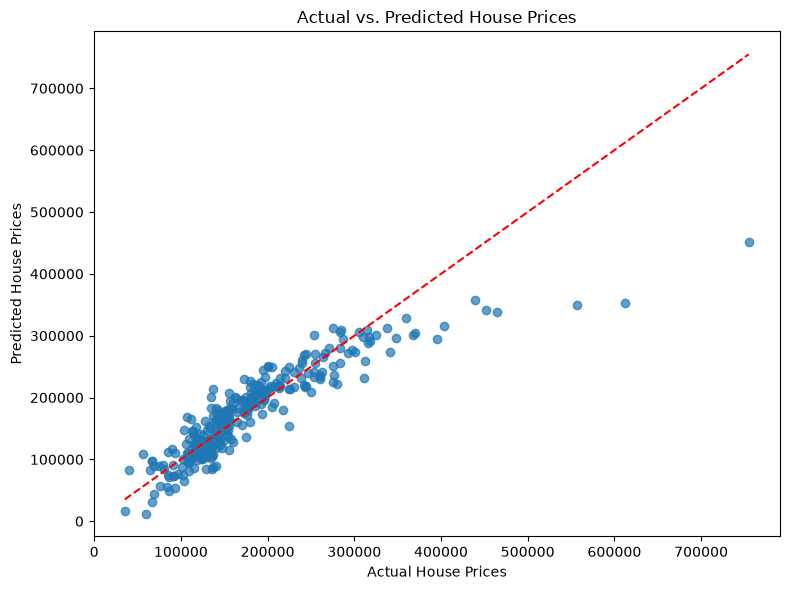

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs. Predicted House Prices")

plt.tight_layout()
plt.show()

###  Interpretation of Actual vs. Predicted Plot
- Most points are close to the red diagonal line, meaning the model predicts many house prices reasonably well.
- Some expensive houses are below the line, meaning the model underestimates their actual prices.
- Overall, the graph supports our R² score of 0.7975.

## 14. Residual Plot

Residuals represent the difference between actual and predicted house prices.

The residual is calculated using the following formula:

$$
\text{Residual}_i = y_i - \hat{y}_i
$$

Where:

- $y_i$ = Actual house price
- $\hat{y}_i$ = Predicted house price
- $i$ = Individual house observation

A residual plot helps identify patterns or errors in the model's predictions. Ideally, 
residuals should be randomly distributed around zero.


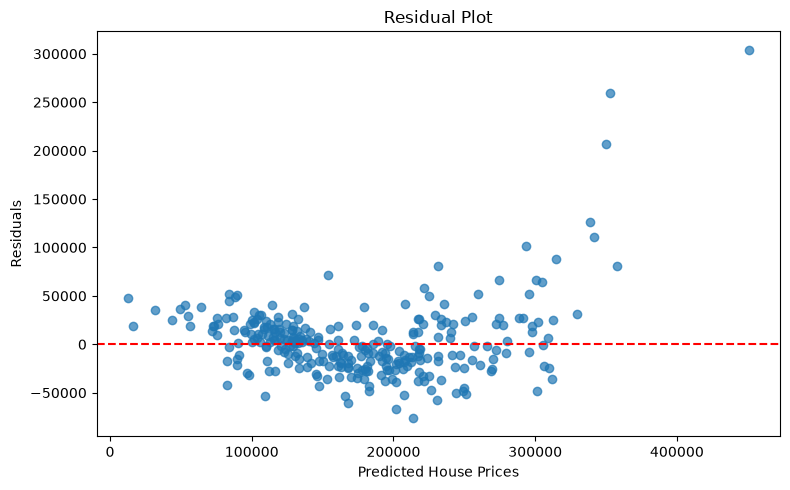

In [17]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.tight_layout()
plt.show()

### Interpretation of Residual Plot

The residual plot shows that many prediction errors are distributed around the zero line. However, the residuals become more spread out for higher predicted house prices.

This indicates that the model may have larger errors when predicting expensive houses. The model performs reasonably well overall, but some predictions are less accurate.

## 15. Coefficient Analysis

The coefficients of the Linear Regression model represent the relationship between each selected feature and the predicted house price.

The Linear Regression equation is:

$$
\hat{y} = \beta_0 + \beta_1X_1 + \beta_2X_2 + \cdots + \beta_nX_n
$$

Where:

- $\hat{y}$ = Predicted house price
- $\beta_0$ = Intercept
- $\beta_i$ = Coefficient of each feature
- $X_i$ = Selected input feature

In [18]:
coefficients = pd.DataFrame({ "Feature": X.columns,"Coefficient": model.coef_})

coefficients.sort_values( by="Coefficient", ascending=False)

,Feature,Coefficient
0,OverallQual,18161.043239
2,GarageCars,14888.195926
7,Fireplaces,10492.901987
6,YearRemodAdd,348.883623
5,YearBuilt,268.189853
1,GrLivArea,47.292127
3,TotalBsmtSF,23.741857
4,FullBath,-5679.313566


### 15.1 Interpretation of Coefficients

The coefficient analysis shows how the selected features are associated with house prices, while keeping the other selected features constant.

- **OverallQual:** Has the largest positive coefficient. Higher overall quality is associated with higher predicted house prices.
- **GarageCars:** A higher garage capacity is associated with increased predicted prices.
- **Fireplaces:** More fireplaces are associated with higher predicted prices.
- **YearRemodAdd:** Recent remodeling is associated with higher predicted prices.
- **YearBuilt:** Newer houses tend to have higher predicted prices.
- **GrLivArea:** Larger above-ground living areas are associated with higher predicted prices.
- **TotalBsmtSF:** Larger basement areas are associated with higher predicted prices.
- **FullBath:** Has a negative coefficient in this model. This does not necessarily mean that bathrooms reduce house prices; it may reflect relationships among the selected features.

Overall, most selected features have positive coefficients, indicating a positive relationship with predicted house prices.

Note: The negative FullBath coefficient can occur because features overlap or are correlated.

### 15.2 Visualization of Regression Coefficients

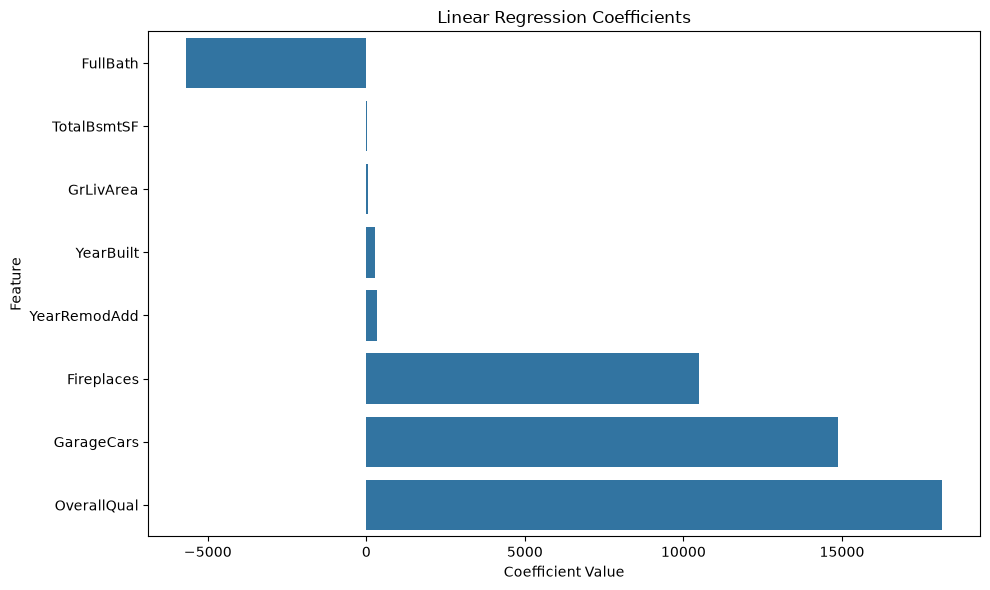

In [19]:
## Visualization
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients.sort_values("Coefficient"),
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Interpretation of Coefficient Visualization
- OverallQual has the largest positive coefficient.
- GarageCars and Fireplaces also have relatively large positive coefficients.
- FullBath has a negative coefficient.
- TotalBsmtSF and GrLivArea have small positive coefficients.

## 16. Conclusion

This project developed a Linear Regression model to predict house prices using selected housing features.

The dataset was explored and analyzed to understand the relationships between house prices and different features. The model was trained using 80% of the data and tested using the remaining 20%.

The model achieved an **R² score of 0.7975**, indicating that it explains approximately 79.75% of the variation in house prices. The RMSE was approximately 39,412.95 price units.

The actual vs. predicted plot showed that the model performs reasonably well for many houses. However, the residual plot revealed larger prediction errors for some expensive houses.

Overall, this project provided practical experience in data preprocessing, exploratory data analysis, feature selection, Linear Regression, and model evaluation.

## 17. Bonus: Ridge and Lasso Regression

Ridge and Lasso Regression are regularization techniques used to reduce overfitting and improve model performance.

- **Ridge Regression (L2):** Reduces the size of coefficients but generally does not make them zero.
- **Lasso Regression (L1):** Can reduce some coefficients to zero, helping with feature selection.

Both models will be evaluated using MSE, RMSE, and R² Score.

In [20]:
from sklearn.linear_model import Ridge, Lasso

In [21]:
# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("MSE:", round(ridge_mse, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R² Score:", round(ridge_r2, 4))

Ridge Regression
MSE: 1553212733.17
RMSE: 39410.82
R² Score: 0.7975


Ridge Regression achieved an R² score of 0.7975, showing almost the same performance as the Linear Regression model.


In [22]:
# Lasso Regression
lasso_model = Lasso(alpha=1.0, max_iter=10000)
lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MSE:", round(lasso_mse, 2))
print("RMSE:", round(lasso_rmse, 2))
print("R² Score:", round(lasso_r2, 4))

Lasso Regression
MSE: 1553363753.3
RMSE: 39412.74
R² Score: 0.7975


Lasso Regression achieved an R² score of 0.7975, showing almost the same predictive performance as the Linear Regression and Ridge Regression models.

### Interpretation of Model Comparison

All three models achieved an R² score of 0.7975, indicating similar predictive performance. Ridge and Lasso Regression did not provide a significant improvement over the Linear Regression model.

This suggests that the original Linear Regression model is sufficient for this dataset, while regularization provides only a minor difference in prediction accuracy.